# 제11교시. ViT: 이미지도 토큰으로 읽을 수 있을까요?


## 이번 교시의 목표

- 픽셀에서 패치 196개를 만들고 CLS를 붙여 197개 위치의 벡터열이 되는 과정을 설명합니다.
- 최종 CLS에서 얻은 1,000개 분류 점수를 모델 출력과 값 수준에서 대조합니다.
- 원본과 반전 이미지의 표현 변화를 관찰하고, 계산 경로 검사와 분류 예측의 타당성을 구분합니다.


## 이번 교시 핵심 용어

- **비전 트랜스포머(vision transformer, ViT)**: 이미지 패치의 벡터열을 Transformer로 처리합니다.
- **패치 임베딩(patch embedding)**: 이미지의 작은 공간 영역을 학습된 벡터로 바꿉니다.
- **분류 토큰(classification token, CLS token)**: 패치 정보를 모아 분류에 사용하는 특별한 시작 토큰입니다.
- **이미지 전처리(image preprocessing)**: 모델 입력에 맞게 이미지 크기·채널·수치 범위를 바꿉니다.
- **분류 헤드(classification head)**: 최종 표현을 클래스별 점수로 바꿉니다.



## 실습 준비

1교시에서 준비한 Windows 프로젝트의 Python 커널을 선택하고 CUDA 환경을 확인합니다. 앞 교시의 모델이 남아 있으면 해당 커널을 종료하고 새 커널에서 시작합니다. 아래 환경 검사와 실제 출력에서 버전·장치를 확인한 뒤 순서대로 실행합니다.

가중치는 지정된 공식 체크포인트와 revision을 사용합니다. 결과 파일은 이 노트북의 `OUT`에 지정된 폴더에 저장하며, 이미지 실습은 코드로 만든 공개 도형만 사용합니다.

**커널·필수 도구:** 1교시에서 만든 프로젝트의 Python 3.12 커널을 선택합니다. 수업 환경은 PyTorch 2.9.1(CUDA 12.6 빌드), Transformers 5.23.0이며 Pillow·NumPy·Matplotlib·huggingface_hub를 사용합니다. 패키지가 없거나 버전이 다르면 이 노트북에서 임의로 업그레이드하지 말고 1교시에서 준비한 환경을 복구한 뒤 커널을 재시작합니다.

**파일·다운로드:** 실행 셀에서 google/vit-base-patch16-224의 고정 revision을 읽습니다. 첫 실행에는 공식 모델 저장소 접속과 가중치 다운로드가 필요하며 이후 같은 다운로드 캐시를 재사용합니다. API 키·유료 추론 API·개인 데이터는 필요하지 않습니다. 연결 오류가 나면 실패 셀을 확인하고 네트워크 복구 뒤 그 셀부터 다시 실행합니다. 인증 토큰을 노트북에 적지 않습니다.

**실행·확인 순서:** 위에서부터 개념과 그림, 코드 설명을 본 뒤 코드 셀을 한 번씩 실행하고 바로 아래 실제 출력·출력 설명을 확인합니다. `assert` 오류가 나오면 뒤 셀로 넘어가지 않습니다. CUDA 사용 불가면 장치·커널을 먼저 확인하고, 메모리 부족이면 결과를 보관한 뒤 이전 모델이 남은 커널을 종료하고 새 커널에서 다시 시작합니다. 이미지나 텍스트의 오답은 환경 오류와 구분합니다.

**결과 보관:** `OUT`과 마지막 저장 경로 출력에서 JSON·그림 폴더를 확인합니다. 실행 횟수와 출력이 남은 `.ipynb`도 저장합니다. 다시 실행해 기록이 중복되면 새 커널에서 처음부터 진행합니다.

앞 교시 Notebook의 커널을 종료해 GPU 메모리를 비우고 이 Notebook 전용 커널을 시작하세요. 새 패키지를 설치하거나 드라이버·설정을 변경하지 않습니다.

처음 사용하는 모델이면 약 346 MB 가중치를 받습니다. 첫 다운로드에 걸리는 시간은 네트워크 상태에 따라 달라집니다. 같은 계정의 캐시가 있으면 재사용합니다. 개인정보가 없는 로컬 도형 이미지만 사용하며 외부 서비스로 이미지를 전송하지 않습니다.


## ViT는 왜 만들었을까요?

2020년 당시 이미지 분류의 특징 추출에는 합성곱 신경망(CNN)이 주로 쓰였습니다. [ViT 논문 §1](https://arxiv.org/html/2010.11929#S1)은 여러 합성곱 층을 쌓아 특징을 뽑는 대신, 이미지를 작은 패치로 나누어 Transformer 인코더에 넣어도 분류할 수 있는지 물었습니다. 전체 범위 셀프 어텐션 덕분에 이미지의 먼 두 패치도 한 인코더 층에서 직접 서로의 정보를 참고할 수 있습니다. 이 실습 구현에도 패치마다 벡터를 만드는 합성곱(Conv2d)이 있지만, 이 한 번의 패치 투영을 여러 층의 CNN 특징 추출과 혼동하지 않습니다.

논문의 핵심 결과는 다음과 같습니다.

**충분히 큰 데이터로 사전학습한 뒤 다른 이미지 분류 과제에 적용했을 때 경쟁력이 있었다.**

예를 들어 [논문 표 2](https://arxiv.org/pdf/2010.11929#page=6)에서는 두 모델을 같은 JFT-300M 데이터로 사전학습한 뒤 ImageNet 분류에 맞춰 추가 학습했을 때, ViT-L/16의 평균 Top-1 정확도는 87.76%, ResNet 기반 BiT-L(ResNet-152×4)은 87.54%였습니다. 이 수치는 실습의 ViT-B/16 점수가 아니며, 데이터 규모와 학습 조건에 관계없이 ViT가 CNN보다 항상 우수하다는 뜻도 아닙니다. 이 실습의 ViT-B/16은 ImageNet의 1,000개 범주 중 무엇이 보이는지 점수로 답하는 분류 모델입니다. 그림을 설명하는 문장을 생성하는 모델은 아닙니다.

## 전체 흐름 먼저 보기: ViT-B/16의 구조

ViT-B/16은 Transformer의 인코더 구조를 이미지에 적용한 모델입니다. 원래 Transformer의 인코더가 단어 토큰의 벡터열을 읽었다면, ViT 인코더는 작은 이미지 영역인 패치의 벡터열을 읽습니다. 양방향 셀프 어텐션, 위치별 MLP(피드포워드 층), 잔차 연결이라는 블록의 설계는 이어받았지만, 번역 모델의 가중치를 가져오는 것이 아니라 이미지에 맞춰 학습한 가중치를 씁니다. 실습 모델은 원래 Transformer의 후행 정규화와 달리 어텐션과 MLP 각각에 들어가기 전에 층 정규화(LayerNorm)를 적용하는 선행 정규화(Pre-LayerNorm)를 사용합니다.

- **B = Base.** 이 모델은 인코더 블록 12개, 토큰 벡터 폭 768, 어텐션 헤드 12개의 Base 규격입니다.
- **/16은 패치 한 변이 16픽셀**이라는 뜻입니다. 224×224 입력에서 패치 벡터 196개를 만들고 그 앞에 학습된 분류용 CLS 벡터 하나를 붙입니다. 위치 임베딩을 더해도 위치 수는 197개로 그대로입니다.

GPT-2는 다음 토큰을 예측하므로 인과적 셀프 어텐션(causal self-attention)으로 자기 자신과 앞쪽 위치만 참조합니다. ViT에는 미래 위치를 가리는 인과 마스크가 없습니다. 이미지 전체는 한 번에 주어지므로 ViT의 각 위치는 앞뒤 패치와 CLS를 모두 참조할 수 있습니다. 이 실습의 이미지 분류 모델에는 디코더가 없습니다. 인코더와 최종 정규화를 지난 첫 위치의 CLS 벡터를 분류 헤드에 넣어 ImageNet 클래스 점수 1,000개를 한 번에 계산합니다.

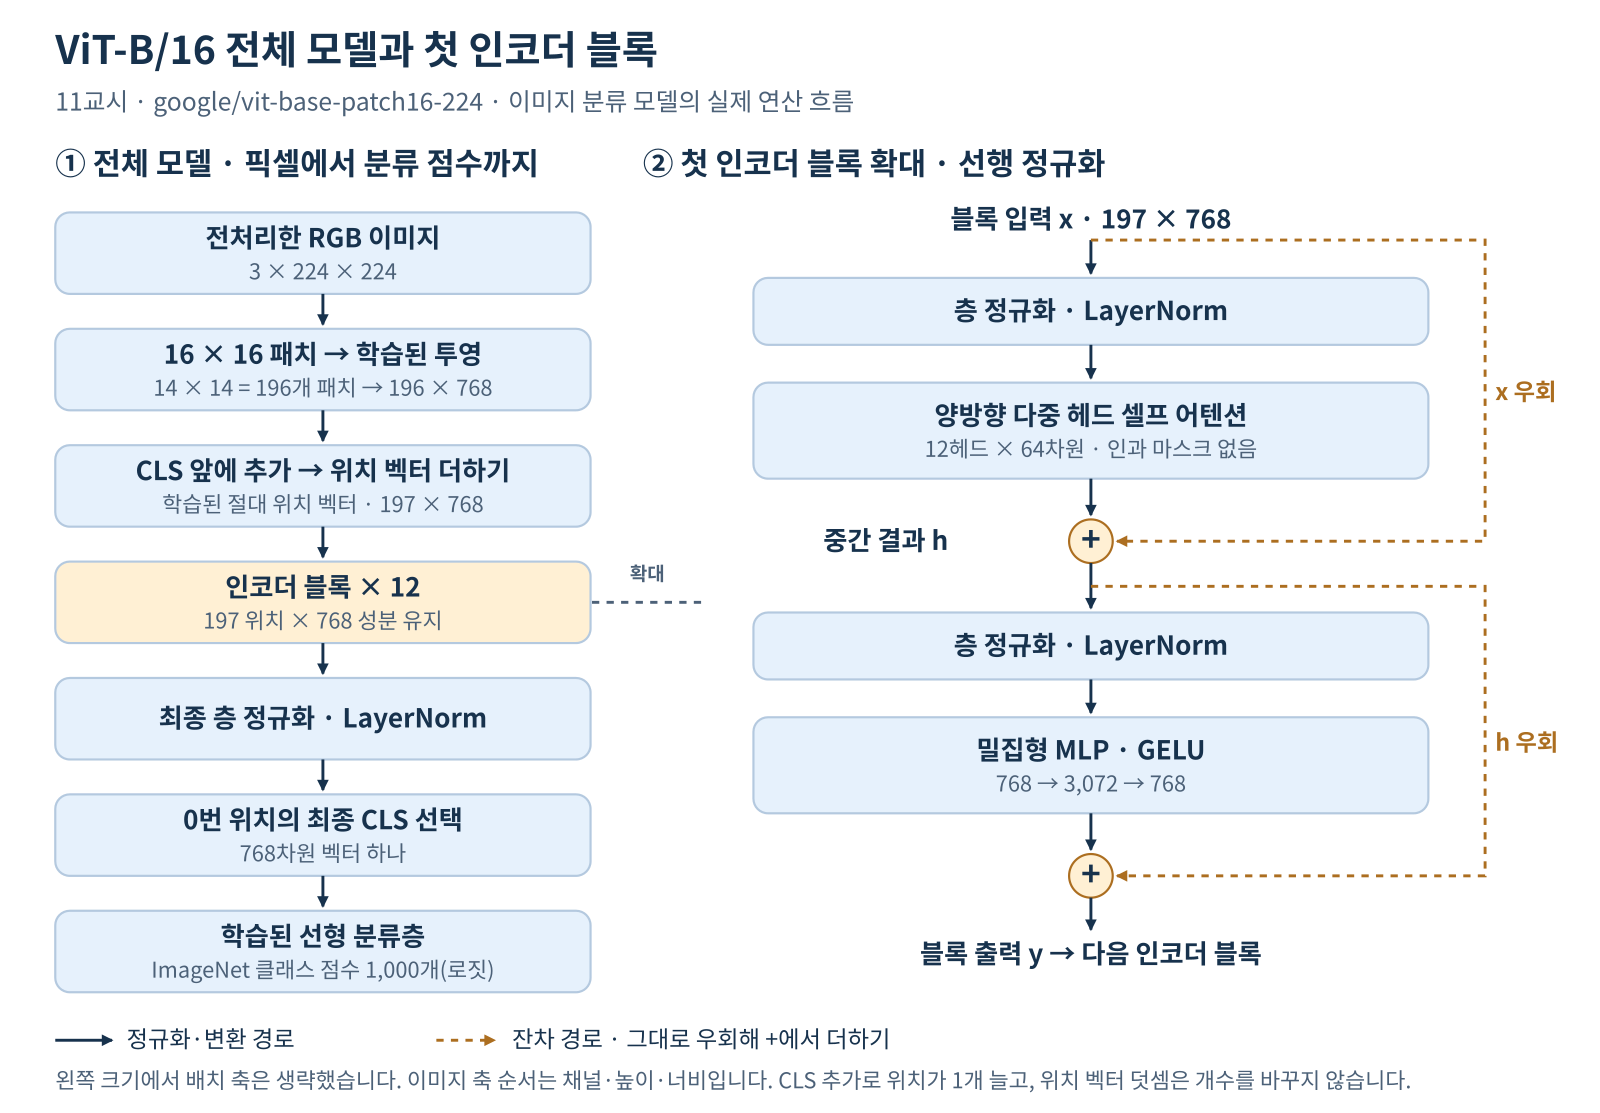

**그림 설명:** 왼쪽은 이미지 전처리 이후부터 분류 점수까지의 전체 흐름, 오른쪽은 그중 첫 인코더 블록입니다. 오른쪽의 두 우회 경로는 각각 원래 블록 입력과 어텐션 뒤 중간 결과를 우회시켜 변환 결과에 더합니다. §4에서는 패치와 CLS를 더하는 모양을, §5에서는 최종 CLS의 분류 경로를 더 자세히 확인합니다.

### 이전에 배운 Transformer 인코더와 무엇이 같고 다를까요?

둘 다 시퀀스의 각 위치가 다른 위치의 정보를 읽어 표현을 갱신하는 인코더입니다. 달라진 것은 인코더 앞에 무엇을 넣는지, 블록 안에서 어떤 순서로 계산하는지, 마지막 표현을 어디에 쓰는지입니다.

| 비교 항목 | 원본 Transformer(2017) 논문의 인코더 | 이 실습의 ViT-B/16 |
|---|---|---|
| 입력 | 토크나이저로 원문을 토큰 ID로 바꾸고 모델에서 임베딩을 조회 | 전처리한 이미지의 16×16 픽셀 패치를 모델 안에서 벡터로 투영하고 CLS 추가 |
| 위치 정보 | 사인·코사인 공식으로 계산한 절대 위치 벡터를 더함 | 학습된 절대 위치 임베딩을 패치와 CLS 벡터에 더함 |
| 블록 공통점 | 양방향 다중 헤드 셀프 어텐션 → 위치별 FFN. 두 서브층에 각각 잔차 연결 | 같은 기본 흐름과 두 잔차 연결 |
| 블록 차이 | 잔차를 더한 뒤 층 정규화(Post-LN), FFN의 ReLU | 각 서브층에 넣기 전 층 정규화(Pre-LN), MLP의 GELU |
| 출력 사용 | 모든 원문 위치의 벡터를 디코더의 크로스 어텐션에 제공 | 최종 CLS 벡터 하나를 분류 헤드에 전달. 생성 디코더 없음 |

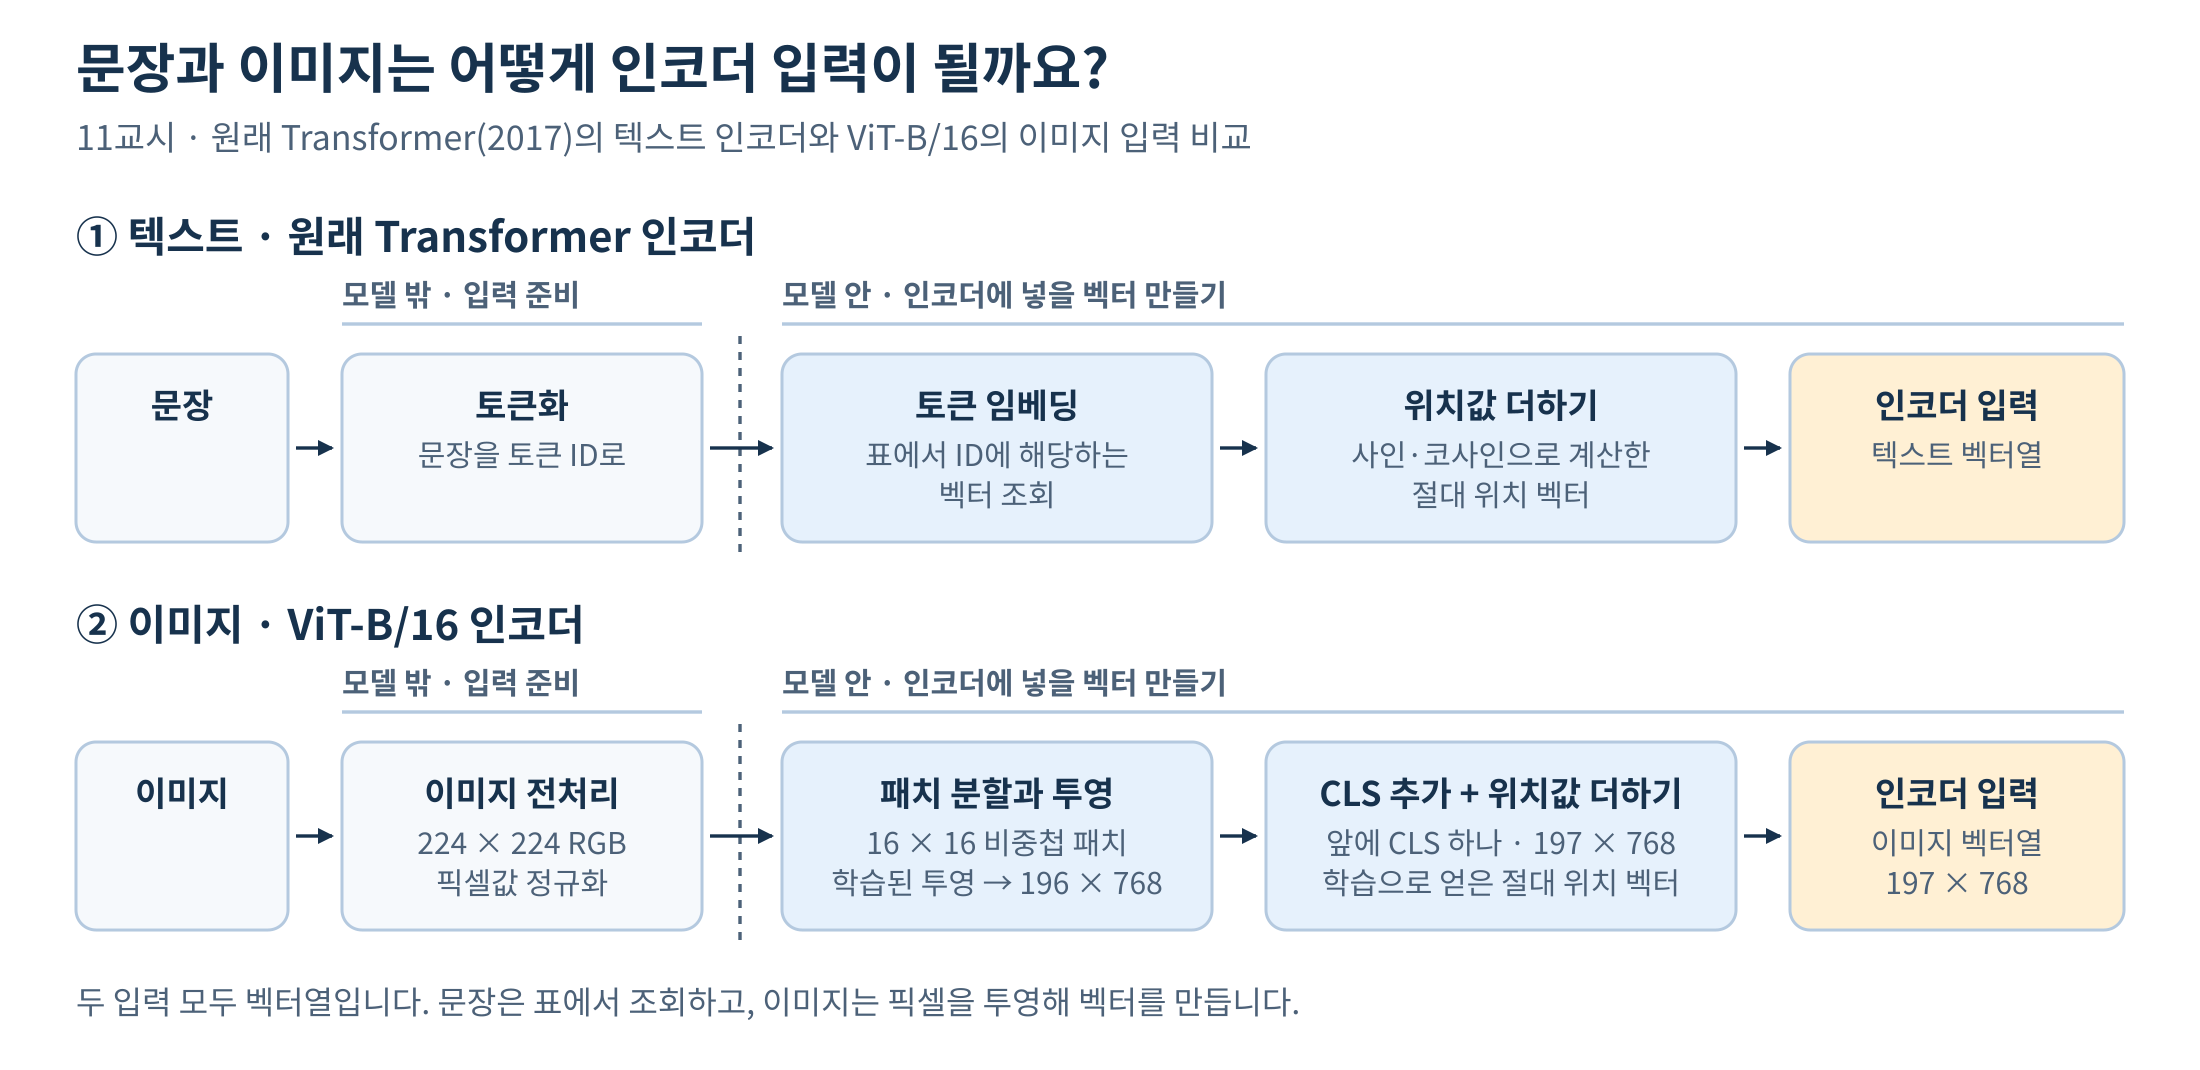

**그림 설명:** 위쪽은 문장, 아래쪽은 이미지가 인코더에 들어가기 전까지의 과정입니다.

**위쪽 | 문장:** 토크나이저가 문장을 나눠 토큰 ID를 만듭니다. ID는 벡터가 아니라 임베딩 표에서 벡터를 찾는 번호입니다. 모델은 토큰 ID로 벡터를 찾고, 그 토큰이 문장에서 몇 번째 자리에 있는지에 따라 사인·코사인 공식으로 계산한 위치 벡터를 더합니다.

**아래쪽 | 이미지:** 전처리기는 RGB 이미지를 224×224로 맞추고 픽셀값을 재조정·정규화합니다(§3). 이 단계의 결과는 아직 픽셀입니다. 모델 안에서 이미지를 겹치지 않는 16×16 패치 196개로 나누고, 패치 하나를 벡터 하나로 바꿉니다(§4). 맨 앞에 CLS 벡터를 붙인 뒤, 197개 자리 각각에 맞는 위치 벡터를 학습된 표에서 가져와 더합니다.

두 인코더 모두 위치 정보가 더해진 벡터열을 받습니다. 둘 다 각자의 자리 번호인 절대 위치를 쓰지만, 원래 Transformer는 위치 벡터를 공식으로 계산하고 ViT는 학습된 표에서 가져옵니다.

비교 기준은 원본 Transformer 논문의 [§3.1 인코더](https://arxiv.org/html/1706.03762#S3.SS1), [§3.3 FFN](https://arxiv.org/html/1706.03762#S3.SS3), [§3.5 위치 인코딩](https://arxiv.org/html/1706.03762#S3.SS5)입니다. 잔차 연결까지 포함한 인코더의 뼈대는 같지만, ViT는 언어 번역이 아닌 이미지 분류에 맞게 입력과 출력 경로를 바꿨습니다.

**ViT(Vision Transformer)**는 [2020년 10월 22일 처음 공개된 논문](https://arxiv.org/abs/2010.11929)에서 제안됐습니다. 실습에 쓰는 224×224 입력용 **ViT-B/16 가중치**는 [2020년 10월 29일](https://github.com/google-research/vision_transformer#changelog)에 공개됐습니다. 구조를 제안한 시점과 이 가중치를 공개한 시점은 다릅니다.


## 1. 환경 확인
필수 버전을 확인하고 CUDA를 선택합니다. 버전 불일치는 임의 업데이트하지 말고 1교시 환경과 비교합니다. CUDA가 아니면 FAIL입니다. 모델 학습은 하지 않으므로 gradient를 저장하지 않습니다.

### 코드 설명: 라이브러리와 실행 장치 확인

첫 셀은 라이브러리와 실행 장치·정밀도를 확인합니다. 출력되는 버전과 장치 정보를 실행 증거로 읽고, `DTYPE`이 뒤의 이미지 텐서와 모델에 공통으로 적용된다는 점을 확인하세요. 환경 검사를 통과했다는 사실과 이미지 분류를 잘한다는 사실은 별개입니다.


In [1]:
# 이미지 표현의 구조를 확인하는 실습이며 별도의 재학습은 수행하지 않습니다.
import sys, platform, json, gc, time
from pathlib import Path
import numpy as np
import torch, transformers
from PIL import Image, ImageDraw
assert platform.system() == "Windows", "이 실습은 Windows 11 x64용입니다."
assert sys.version_info[:2] == (3, 12), "프로젝트 Python 3.12 커널을 선택하세요."
assert torch.__version__.split("+")[0] == "2.9.1", "수업 기준 PyTorch 버전을 확인하세요."
assert torch.version.cuda == "12.6", "수업 기준 cu126 설치를 확인하세요."
assert transformers.__version__ == "5.23.0", "수업 기준 Transformers 버전을 확인하세요."
assert torch.cuda.is_available(), "CUDA 사용 불가: CPU 실행은 PASS가 아닙니다."
# 난수 시작점을 고정하지만 다른 장치·라이브러리의 완전히 동일한 수치까지 보장하지는 않습니다.
torch.manual_seed(42)
# 아래 모델과 입력 텐서를 같은 CUDA 장치에 두기 위한 공통 설정입니다.
DEVICE = "cuda"
# 이후 모델 가중치와 실수 픽셀 텐서에 같은 자료형을 적용합니다.
DTYPE = torch.float32
print("[PASS] environment", torch.__version__, transformers.__version__, torch.cuda.get_device_name(0))

%USERPROFILE%\AI-Engineering\python31210-signed-qa-20261117\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[PASS] environment 2.9.1+cu126 5.23.0 NVIDIA GeForce RTX 4090


### 출력 설명

저장된 출력은 PyTorch 2.9.1+cu126·Transformers 5.23.0, RTX 4090에서 실행한 기록입니다. 이 장치에서 통과한 기록을 다른 GPU의 속도나 메모리 충분함에 대한 보장으로 읽지 않습니다. 

환경 PASS가 출력됐지만 이미지나 모델을 아직 읽지 않은 셀입니다. 이후 이미지·가중치 로드와 분류 경로 검사를 통과해야 이 환경에서 실제 ViT 실행을 확인할 수 있습니다.

IProgress 경고는 진행 막대용 위젯을 찾지 못했다는 안내입니다. 이 기록은 이후 PASS까지 진행했으므로 가중치나 CUDA 계산 실패의 증거가 아닙니다.


## 2. 원본 이미지 만들기
빨간 사각형과 파란 원을 직접 그립니다. 이 도형은 입력 흐름을 통제하기 위한 fixture(고정 예제)입니다. ImageNet 정답 분류나 시각 정확도를 평가하는 이미지가 아닙니다.

### 픽셀 하나는 숫자 세 개입니다

도형 내부 한 점을 확대했다고 생각해 보세요. RGB 픽셀 하나에는 빨강(R), 초록(G), 파랑(B)의 세 값이 있습니다. 실제 코드에서 빨간 사각형 내부는 `(220, 35, 35)`, 파란 원 내부는 `(35, 80, 220)`, 흰 배경은 `(255, 255, 255)`로 채웁니다. 빨간 점의 첫 값이 다른 두 값보다 커서 빨강이 강하게 보입니다. 이 값은 색의 세기이지 클래스 번호가 아닙니다.

다음 절의 전처리기는 저장한 RGB 원본을 받습니다.


### 코드 설명: 도형 배치를 눈으로 확인할 수 있는 입력

`Image.new`로 RGB 원본을 만들고 `ImageDraw`로 두 도형을 그립니다. 원본을 먼저 저장하고 화면 표시용 사본만 줄입니다.


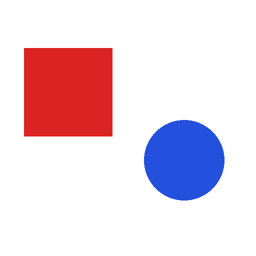

[PASS] local RGB fixture (512, 512)


In [2]:
# 외부 사진을 받지 않고 학습용 기하 도형을 직접 만듭니다.
# 같은 입력을 반복 생성하고 예측 내용도 눈으로 점검할 수 있도록 단순한 도형을 만듭니다.
# PIL 크기는 (너비,높이)이며 아직 배치 축이 있는 모델 입력 텐서가 아닙니다.
image = Image.new("RGB", (512, 512), "white")
draw = ImageDraw.Draw(image)
draw.rectangle((48, 96, 224, 272), fill=(220, 35, 35))
# 경계 상자의 너비와 높이가 같아 원이 됩니다. RGB 숫자는 색 값이지 클래스 번호가 아닙니다.
draw.ellipse((288, 240, 448, 400), fill=(35, 80, 220))
OUT = Path("results")
# 상위 폴더까지 생성하고 원본 그림·구조 기록을 이번 실행 폴더에 모읍니다.
OUT.mkdir(exist_ok=True)
image.save(OUT / "geometric-fixture.png")
# 표시만 256×256으로 줄이며 원본 image는 512×512로 유지합니다.
display(image.resize((256, 256)))
print("[PASS] local RGB fixture", image.size)

### 출력 설명

화면에는 흰 바탕의 왼쪽 위 빨간 사각형과 오른쪽 아래 파란 원이 보입니다. 이 실제 그림을 나중의 분류 예측과 대조할 기준으로 사용합니다. 출력 이미지의 표시 크기는 256×256이지만 PASS에 기록된 원본은 512×512입니다. 표시용 축소본과 원본을 구분하면 뒤의 전처리 크기를 잘못 계산하지 않을 수 있습니다.

이 출력은 직접 만든 시험 이미지가 준비됐다는 확인입니다. 자연 사진 데이터셋의 정답 라벨을 제공하거나 분류 정확도를 측정한 결과가 아닙니다.


## 3. 실제 모델과 전처리

이 절에서는 모델이 받을 픽셀을 준비하고 학습된 분류 모델을 불러옵니다. 아직 픽셀을 패치 벡터로 바꾸거나 예측을 만들지는 않습니다.

### 사진을 모델 입력으로 바꾸기

**크기를 맞추기:** Pillow 전처리기는 512×512 원본을 224×224픽셀 격자로 다시 표현합니다. 크기를 줄일 때 도형의 경계에서는 주변 픽셀값이 섞일 수 있습니다. 다음 절의 패치 수는 이 224×224를 기준으로 셉니다.

**픽셀값을 바꾸기:** 크기를 맞춘 뒤에는 좌표를 움직이지 않습니다. 각 픽셀의 빨강·초록·파랑 채널값에 아래 계산을 적용합니다.

- **255로 나누기:** 채널값의 범위를 0~255에서 0~1로 바꿉니다. 크기를 바꾼 뒤에도 빨간 사각형 안쪽 한 점의 빨강 값이 220이라고 가정하면, `220 ÷ 255 ≈ 0.863`입니다.
- **0.5 빼기:** 0~1의 중간값인 0.5를 0으로 옮깁니다. 범위는 −0.5~+0.5가 됩니다.
- **0.5로 나누기:** 다시 범위를 −1~+1로 맞춥니다. 0, 0.5, 1은 각각 −1, 0, +1이 되고, 예시의 빨강 값은 `(220 ÷ 255 − 0.5) ÷ 0.5 ≈ 0.725`가 됩니다.

[고정 전처리 설정](https://huggingface.co/google/vit-base-patch16-224/blob/3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3/preprocessor_config.json)에 따르면, 먼저 빼는 0.5는 채널별 평균(`image_mean`), 그다음 나누는 0.5는 채널별 표준편차(`image_std`)입니다. 세 채널 모두 평균과 표준편차가 0.5로 고정되어 있고, 지금 넣은 사진에서 새로 계산한 값이 아닙니다. 초록·파랑에도 같은 규칙을 적용해 학습 때와 같은 입력 스케일을 맞춥니다. 픽셀 위치나 텐서 모양은 그대로입니다. 0.725는 이 규칙을 보여 주는 계산 예로, 이 셀에서 출력한 값은 아닙니다.

### 전처리기와 분류 모델은 서로 다른 물건입니다

둘 다 같은 저장소의 고정 revision을 사용합니다. 다만 전처리기는 **이미지 입력 규칙**, 분류 모델은 **사전학습·분류 가중치**를 읽습니다. 전처리기 출력은 아직 픽셀이며, 그 픽셀을 패치 벡터로 변환하는 일은 §4에서 모델 내부의 학습된 층이 합니다.


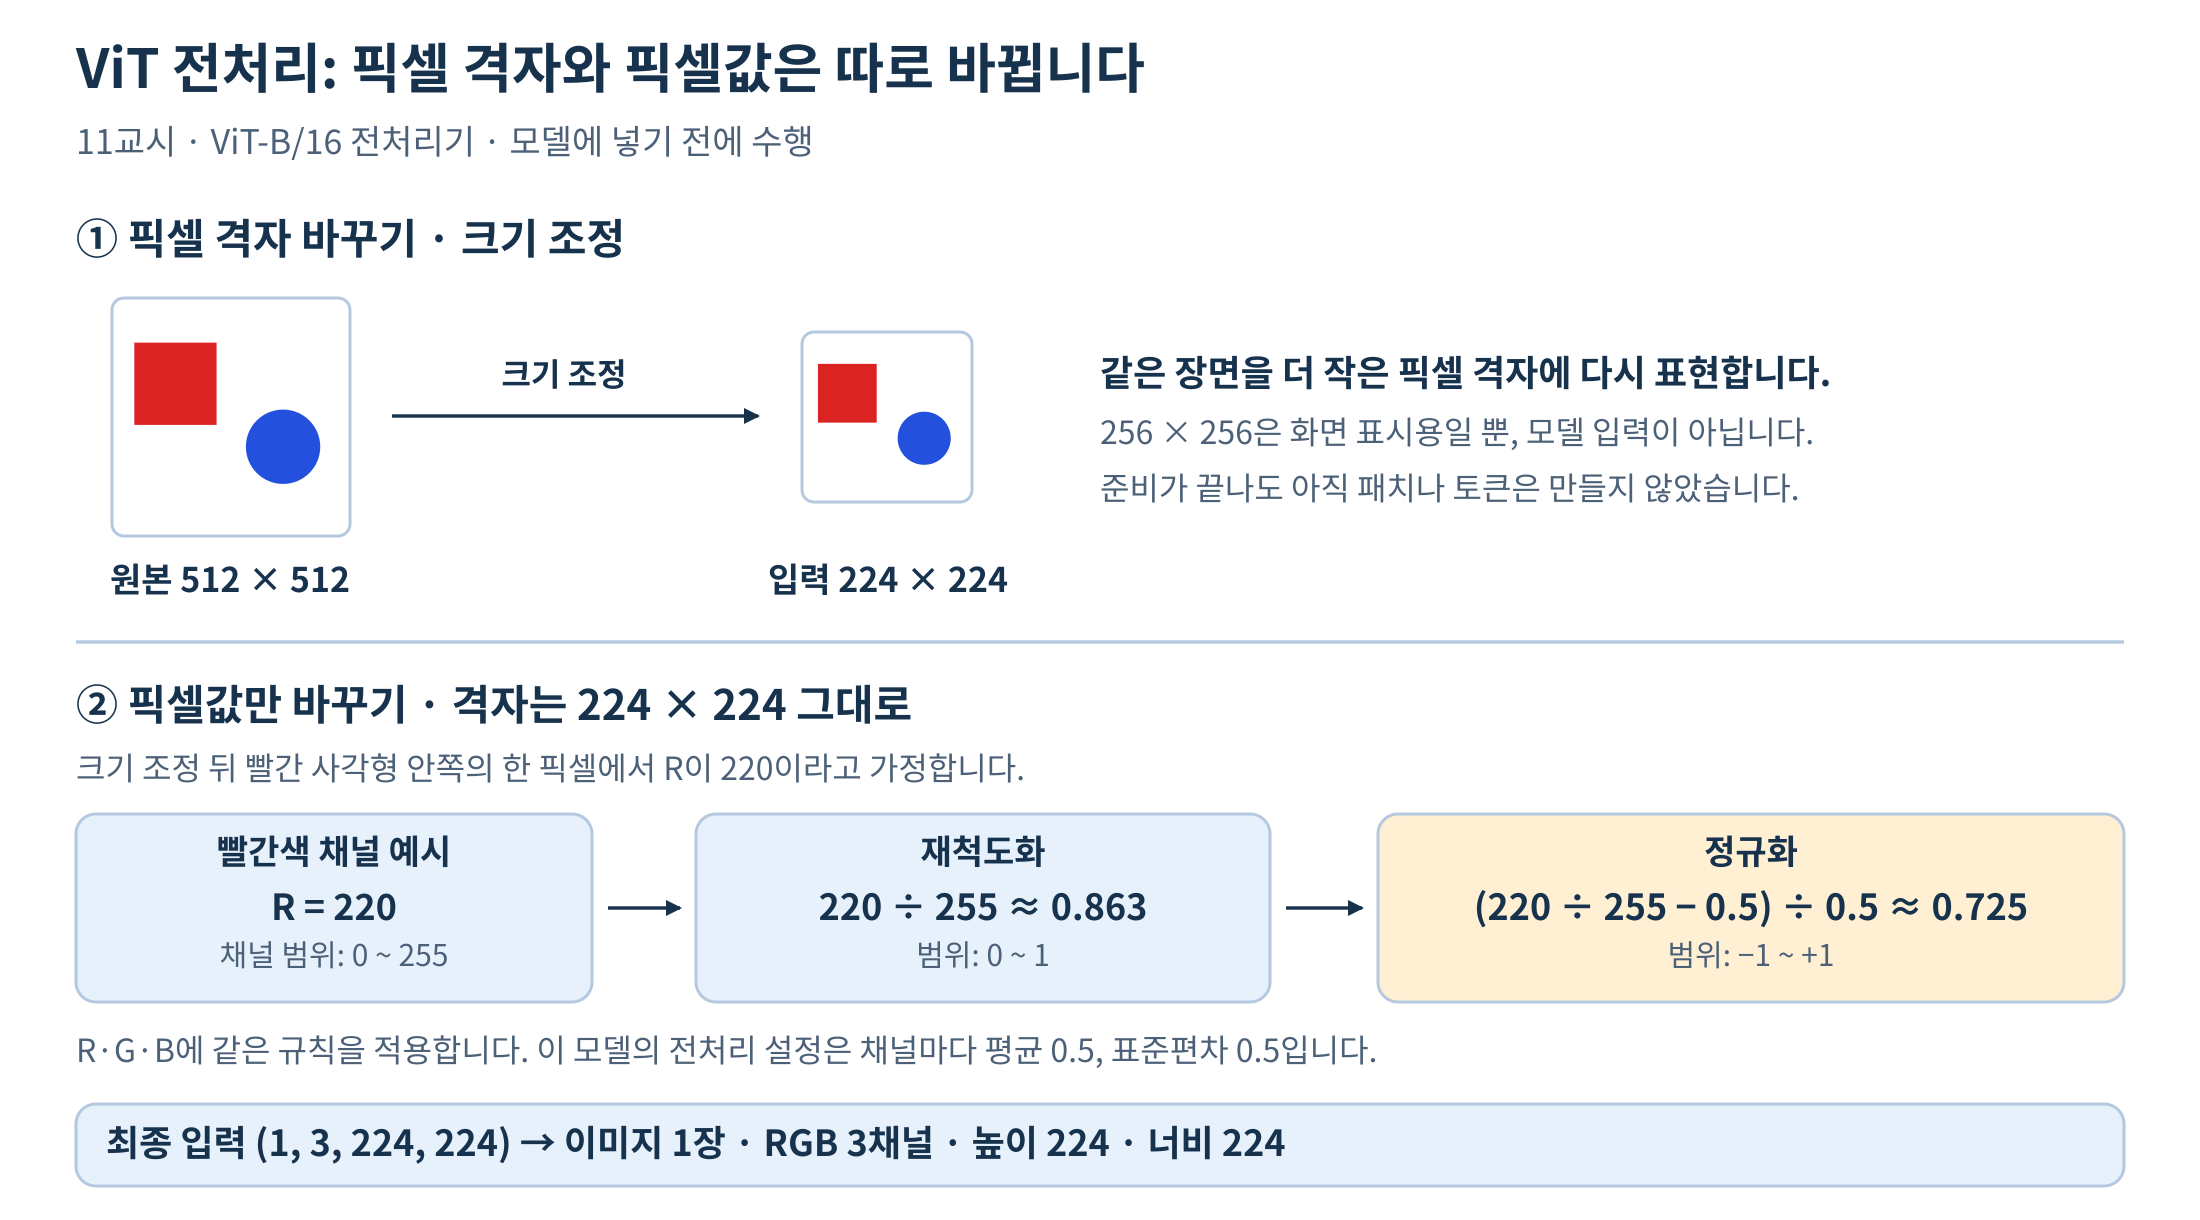

**그림 설명:** 원본에서 모델 입력으로 이어지는 화살표를 따라가 보세요. 미리보기는 이 경로에 들어가지 않습니다. 아래 계산은 모델 입력 격자를 움직이지 않고 채널값만 바꿉니다.


### 코드 설명: 픽셀 텐서와 가중치 준비하기

- `ViTImageProcessorPil.from_pretrained(...)`는 전처리 규칙을 읽습니다. `processor(images=image, return_tensors="pt")`에 원본을 주면 PyTorch 형식의 `pixel_values`가 나옵니다.
- `ViTForImageClassification.from_pretrained(...)`는 같은 revision에서 인코더와 분류층의 가중치를 읽습니다. `.eval()`은 모델을 평가 모드로 전환합니다. 이후 순전파에서 미분을 기록하지 않는 일은 별도의 `inference_mode()`가 맡습니다.
- `pixels`를 모델과 같은 계산 장치·FP32에 놓고 텐서 모양과 모델 설정을 검사합니다. `patch_size=16`은 다음 절에서 나눌 패치 한 변이고, `hidden_size=768`은 패치 투영 뒤 벡터의 폭입니다.


In [3]:
from transformers.models.vit.image_processing_pil_vit import ViTImageProcessorPil
from transformers import ViTForImageClassification
MODEL_ID = "google/vit-base-patch16-224"
REVISION = "3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3"
# 학습 체크포인트의 전처리 규칙을 읽어 모델이 사용하는 크기·수치 범위를 맞춥니다.
processor = ViTImageProcessorPil.from_pretrained(MODEL_ID, revision=REVISION, token=False)
# 인코더뿐 아니라 학습된 분류층까지 읽습니다. logits의 1000개 값은 어휘가 아니라 클래스 점수입니다.
model = ViTForImageClassification.from_pretrained(
    MODEL_ID, revision=REVISION, token=False, use_safetensors=True,
    dtype=DTYPE, attn_implementation="sdpa"
).to(DEVICE).eval()
# 원본 이미지 크기와 모델 입력 크기는 다르므로 전처리 뒤 shape를 확인합니다.
inputs = processor(images=image, return_tensors="pt")
# (배치,채널,높이,너비) 텐서를 모델과 같은 장치·자료형으로 옮깁니다.
pixels = inputs["pixel_values"].to(DEVICE, dtype=DTYPE)
assert tuple(pixels.shape) == (1, 3, 224, 224)
# 입력 크기·패치 크기·벡터 폭이 뒤에서 해석할 14×14 격자와 768차원 조건인지 확인합니다.
assert model.config.patch_size == 16 and model.config.hidden_size == 768
print("pixel_values:", tuple(pixels.shape))
print("parameters:", sum(p.numel() for p in model.parameters()))
print("model/revision:", MODEL_ID, REVISION)
print("[PASS] actual pretrained ViT loaded")

W1117 22:11:59.006000 34808 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 44323.20it/s]

pixel_values: (1, 3, 224, 224)
parameters: 86567656
model/revision: google/vit-base-patch16-224 3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3
[PASS] actual pretrained ViT loaded


### 출력 설명

실행 출력의 `pixel_values: (1, 3, 224, 224)`는 배치(한꺼번에 처리하는 이미지) 1장, RGB 채널 3개, 높이와 너비 각각 224픽셀을 뜻합니다. `parameters: 86567656`은 불러온 모델의 파라미터 수이며, 이미지의 픽셀 수나 패치 토큰 수가 아닙니다. `model/revision`과 로드 PASS는 선택한 체크포인트가 준비됐다는 뜻이지, 이미지를 분류했다는 결과는 아닙니다.

프로세스 출력 리다이렉션 미지원 안내가 함께 기록됐지만 모델 로드·검사는 완료됐습니다. 이 메시지를 모델의 추론 실패나 수업에 필요한 분산 실행 설정으로 해석하지 않습니다.


## 4. 픽셀 격자에서 197개 토큰으로

### 전처리한 이미지 한 장은 왜 토큰 197개가 되나요?

§3에서 만든 RGB 픽셀 텐서 `(1, 3, 224, 224)`가 출발점입니다. 위치 수와 벡터 폭을 따로 따라가 보세요.

1. **겹치지 않는 패치 196개로 나눕니다.** 가로·세로 모두 16픽셀씩 나누면 한 방향에 `224 ÷ 16 = 14`칸, 전체는 `14 × 14 = 196`칸입니다. 여기까지 패치 한 칸은 픽셀 묶음입니다.
   **커널과 스트라이드는 어떻게 다를까요?** 커널 크기(kernel size)는 한 번에 보는 픽셀 영역이고, 스트라이드(stride)는 그 영역의 시작점을 다음 위치까지 옮기는 간격입니다. 이 모델은 16×16 영역을 가로와 세로로 16픽셀씩 옮깁니다. 크기와 간격이 같아 이웃 패치의 경계가 맞닿지만 픽셀은 겹치지 않습니다.

   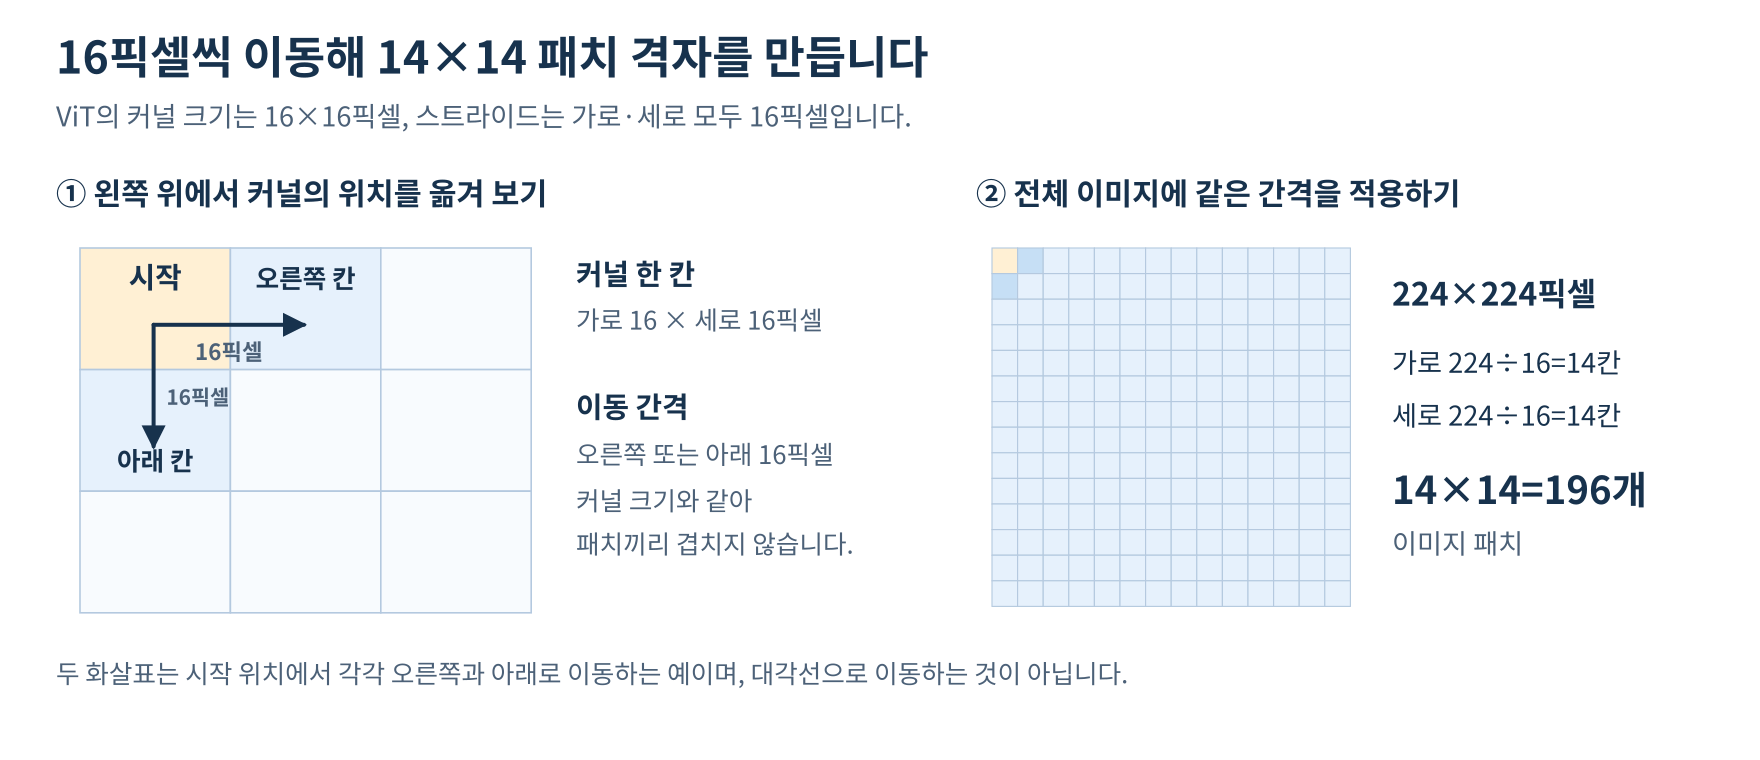

   **그림 설명:** 같은 시작 위치에서 오른쪽 칸으로 가면 열 번호만 0~15에서 16~31로 바뀌고, 아래 칸으로 가면 행 번호만 그렇게 바뀝니다. 오른쪽 그림은 이 간격으로 전체 이미지를 덮은 격자입니다.

2. **패치 하나를 벡터 하나로 바꿉니다.** `/16`은 패치 크기를 뜻하므로 입력 숫자 수는 RGB 채널까지 세어 `16 × 16 × 3 = 768`입니다. 학습된 합성곱층(Conv2d)은 각 위치에서 같은 필터를 적용합니다. 필터 하나가 768개 숫자의 가중합에 자기 편향을 더해 출력 성분 하나를 만듭니다. 이렇게 필터 768개의 출력을 모아 768차원 패치 벡터를 만듭니다. 이 실습에서 두 수가 같다고 픽셀값을 그대로 복사하는 것은 아닙니다.

   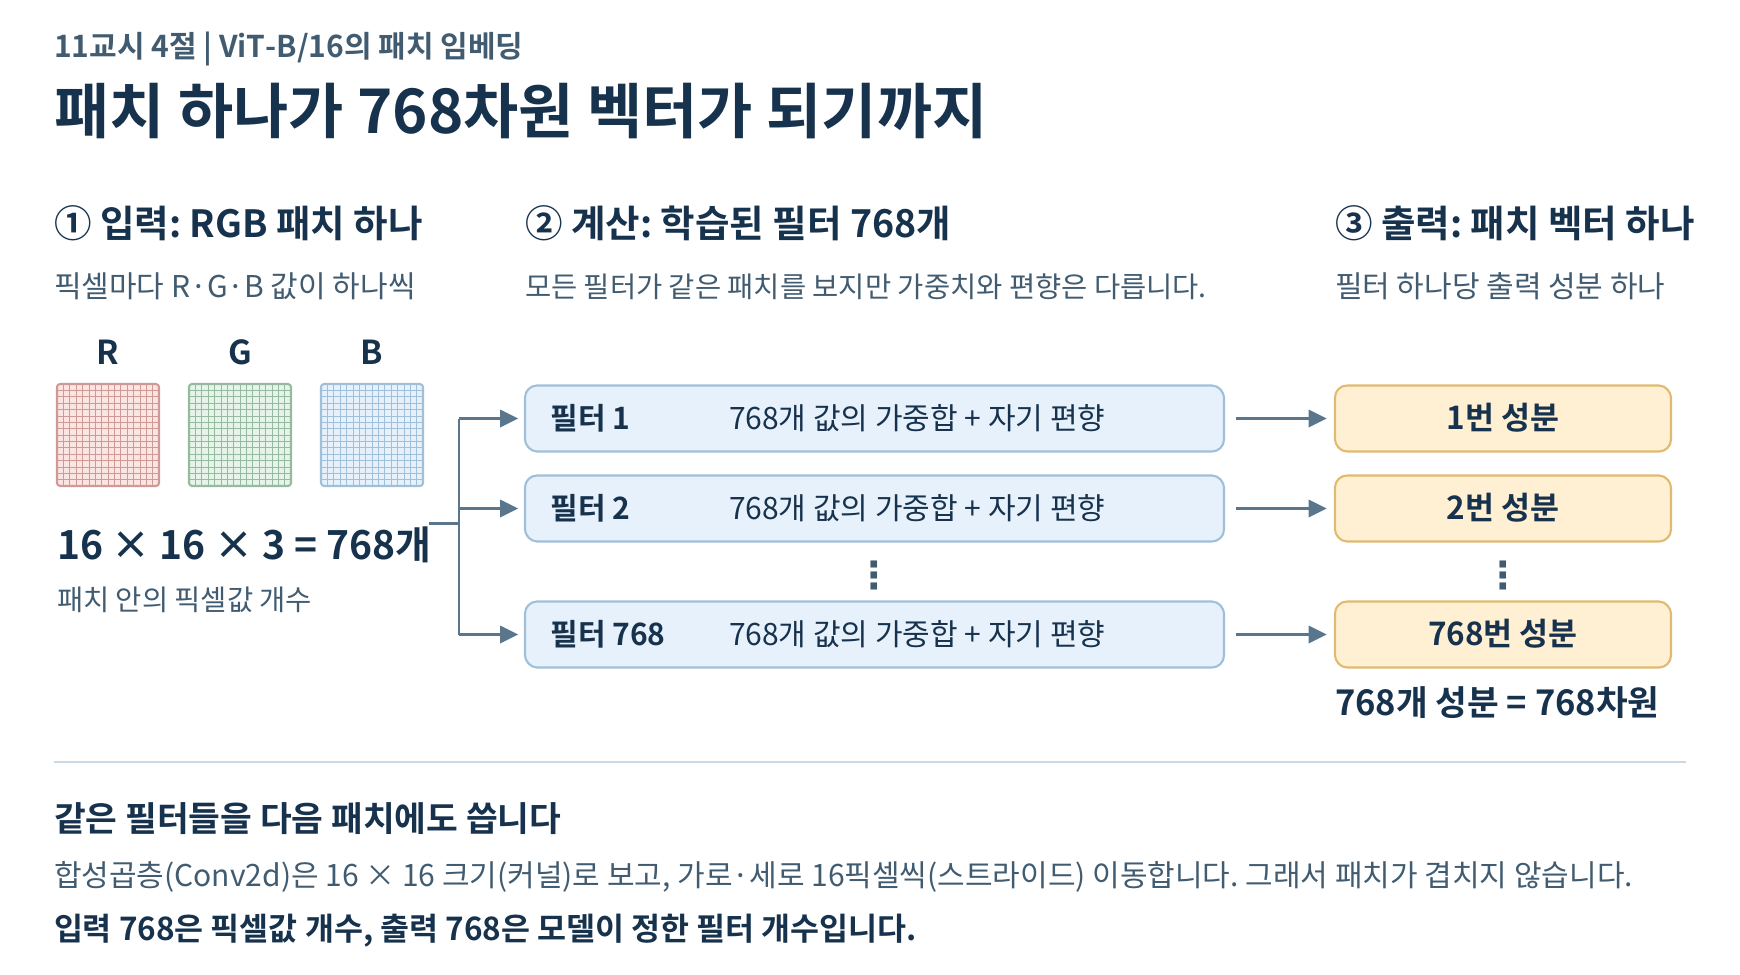

   **그림 설명:** 왼쪽 세 격자는 같은 패치의 R·G·B 채널입니다. 가운데 필터 1, 2, 768에서 오른쪽 성분 하나씩으로 이어지는 화살표를 보세요. 다음 패치에서는 같은 필터를 새 입력값에 적용합니다.

   **참고: 왜 768차원일까요?** 출력 폭 `hidden_size=768`은 별도의 설계입니다. [ViT 논문 §4.1과 표 1](https://arxiv.org/pdf/2010.11929#page=5)에 따르면 `B`(Base)는 BERT의 모델 규격을 참고해 폭 768, 인코더 12층, 어텐션 헤드 12개, MLP 중간 폭 3,072를 채택했습니다. BERT의 가중치를 가져온 것은 아니며, 같은 /16인 ViT-L/16의 출력 폭은 1,024입니다.


3. **14×14 벡터 격자를 한 줄로 펼칩니다.** 투영 직후엔 `(1, 768, 14, 14)`(배치, 특징, 행, 열)입니다. 각 행을 왼쪽에서 오른쪽으로, 위 행부터 차례로 펼쳐 한 위치 축으로 만든 뒤 위치와 특징 축을 바꿔 `(1, 196, 768)`로 만듭니다. 계산된 특징값은 바뀌지 않고 배치 방식만 바뀝니다.
4. **맨 앞에 CLS 하나를 붙입니다.** 학습된 768차원 CLS 벡터를 앞에 붙이면 위치 수가 `196 + 1 = 197`이 됩니다. 이제 모양은 `(1, 197, 768)`입니다.
5. **각 자리에 위치 벡터를 더합니다.** 0번은 CLS, 1번은 왼쪽 위 패치, 2번은 그 오른쪽, 15번은 둘째 행 첫 패치입니다. 학습된 절대 위치 표에서 자리 번호에 맞는 768차원 벡터를 꺼내 기존 벡터에 성분별로 더합니다. 새 위치를 붙이는 것이 아니므로 모양은 그대로 `(1, 197, 768)`입니다.


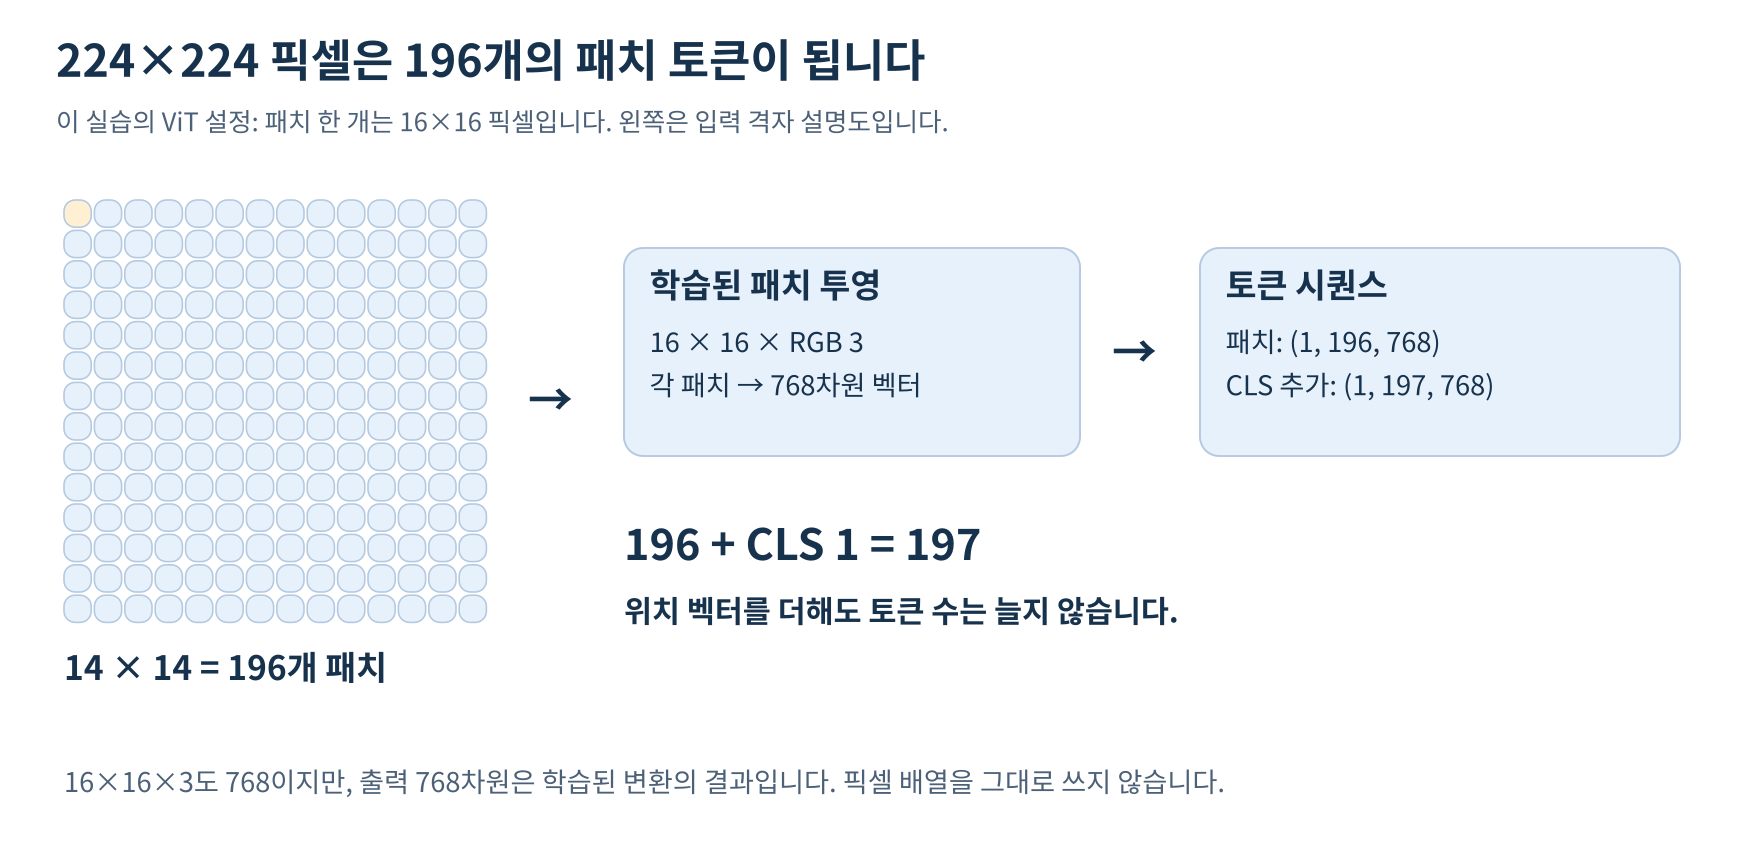

**그림 설명:** 왼쪽 14×14 격자는 패치 위치 196곳입니다. 한 줄로 펼친 뒤 맨 앞에 CLS 하나를 붙여 197곳을 만듭니다. 위치 벡터는 각 자리에 더하므로 197곳은 그대로입니다.


### 코드 설명: 모듈의 결과와 직접 조립한 결과 비교하기

`projection(pixels)`와 `patch_embeddings(pixels)`는 각각 격자와 패치 벡터열을 확인하는 호출입니다. `emb(pixels)`는 CLS와 위치값까지 포함한 임베딩 모듈의 실제 결과입니다. 같은 패치 벡터를 써서 CLS를 `dim=1`에 붙이고 위치값을 더한 `reconstructed`를 만든 뒤, 세 텐서의 모양과 두 최종 결과의 값을 검사합니다. 필터 가중합을 별도로 다시 계산하는 검사는 아닙니다.


projection grid: (1, 768, 14, 14)
patch tokens: (1, 196, 768)
위치 벡터를 더한 토큰 시퀀스: (1, 197, 768)
[PASS] 196 patches + 1 CLS = 197 tokens


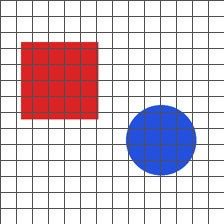

In [4]:
# 픽셀을 16x16 영역으로 나누고 학습된 Conv2d로 768차원에 투영합니다.
emb = model.vit.embeddings
with torch.inference_mode():
    # Conv2d 결과는 (1,768,14,14), 평탄화·전치한 패치는 (1,196,768)입니다.
    projected_grid = emb.patch_embeddings.projection(pixels)
    patch_tokens = emb.patch_embeddings(pixels)
    # 패치 투영만이 아니라 CLS 추가와 위치 벡터 덧셈까지 포함한 임베딩 모듈 전체를 실행합니다.
    embeddings = emb(pixels)
    # 학습된 CLS 한 개를 재사용하며 dim=1 결합으로 196+1개 위치가 됩니다.
    cls = emb.cls_token.expand(1, -1, -1)
    # CLS를 추가한 후 위치 벡터를 더하는 순서를 실제 모듈 출력과 대조합니다.
    reconstructed = torch.cat([cls, patch_tokens], dim=1) + emb.position_embeddings
assert tuple(projected_grid.shape) == (1, 768, 14, 14)
assert tuple(patch_tokens.shape) == (1, 196, 768)
assert tuple(embeddings.shape) == (1, 197, 768)
# 직접 재구성한 값과 모듈 반환값을 비교하며 shape만 확인하는 검사가 아닙니다.
# FP32 기본값: |embeddings−reconstructed| ≤ 0.00001+0.0000013×|reconstructed|.
torch.testing.assert_close(embeddings, reconstructed)
print("projection grid:", tuple(projected_grid.shape))
print("patch tokens:", tuple(patch_tokens.shape))
print("위치 벡터를 더한 토큰 시퀀스:", tuple(embeddings.shape))
print("[PASS] 196 patches + 1 CLS = 197 tokens")
# 격자는 모델 입력으로 쓰지 않고 이해를 돕기 위한 별도 그림으로만 저장합니다.
# 모델 전처리 텐서와 별도로 만든 설명용 그림입니다. 격자선을 모델 입력으로 다시 넣지 않습니다.
grid = image.resize((224, 224)).copy()
grid_draw = ImageDraw.Draw(grid)
# 0부터224까지 16픽셀 간격으로 선을 그려 14×14개의 영역을 보여 줍니다.
for k in range(0, 225, 16):
    grid_draw.line((k, 0, k, 223), fill=(80, 80, 80), width=1)
    grid_draw.line((0, k, 223, k), fill=(80, 80, 80), width=1)
grid.save(OUT / "vit-patch-grid.png")
display(grid)

### 출력 설명

- `projection grid: (1, 768, 14, 14)`: 각 격자 칸에 768개의 학습된 특징이 있습니다.
- `patch tokens: (1, 196, 768)`: 그 칸을 한 줄로 나열한 결과입니다.
- `위치 벡터를 더한 토큰 시퀀스: (1, 197, 768)` CLS와 위치 정보까지 포함한 임베딩 모듈 출력입니다.

PASS는 세 모양이 맞고, 직접 조립한 `reconstructed`와 실제 임베딩 모듈의 출력이 원소별로 허용 오차 안에서 일치했다는 뜻입니다. [PyTorch FP32 기본값](https://docs.pytorch.org/docs/2.9/testing.html#torch.testing.assert_close)은 `atol=1e-5`, `rtol=1.3e-6`이며 이 검사에서는 절대 차이가 `0.00001 + 0.0000013 × |reconstructed|` 이하여야 합니다. 최대 차이의 수치를 출력한 것은 아니며 분류 정확도 검사도 아닙니다.

출력의 격자선은 패치 경계를 보여 주려고 224×224 표시용 복사본에 그렸습니다. 어텐션 강도를 표시한 것이 아니고, 그 복사본을 모델에 다시 넣지도 않았습니다.

이제 §5에서 첫 위치인 CLS가 분류에 어떻게 쓰이는지 봅니다.


## 5. 인코더가 읽은 CLS로 분류하기

CLS는 입력에 붙이는 학습된 시작 벡터입니다. 인코더 안에서 패치 정보를 반영하며 값이 바뀌지만, 197개 위치와 각 벡터의 폭 768은 그대로입니다.

분류기는 맨 앞 CLS만 사용합니다. **197→1은 위치 선택**, **768→1,000은 그 벡터를 클래스 점수로 바꾸는 선형 변환**입니다. 이 점수는 ImageNet의 고정 클래스에 대한 로짓이지, 다음 단어에 대한 점수가 아닙니다.


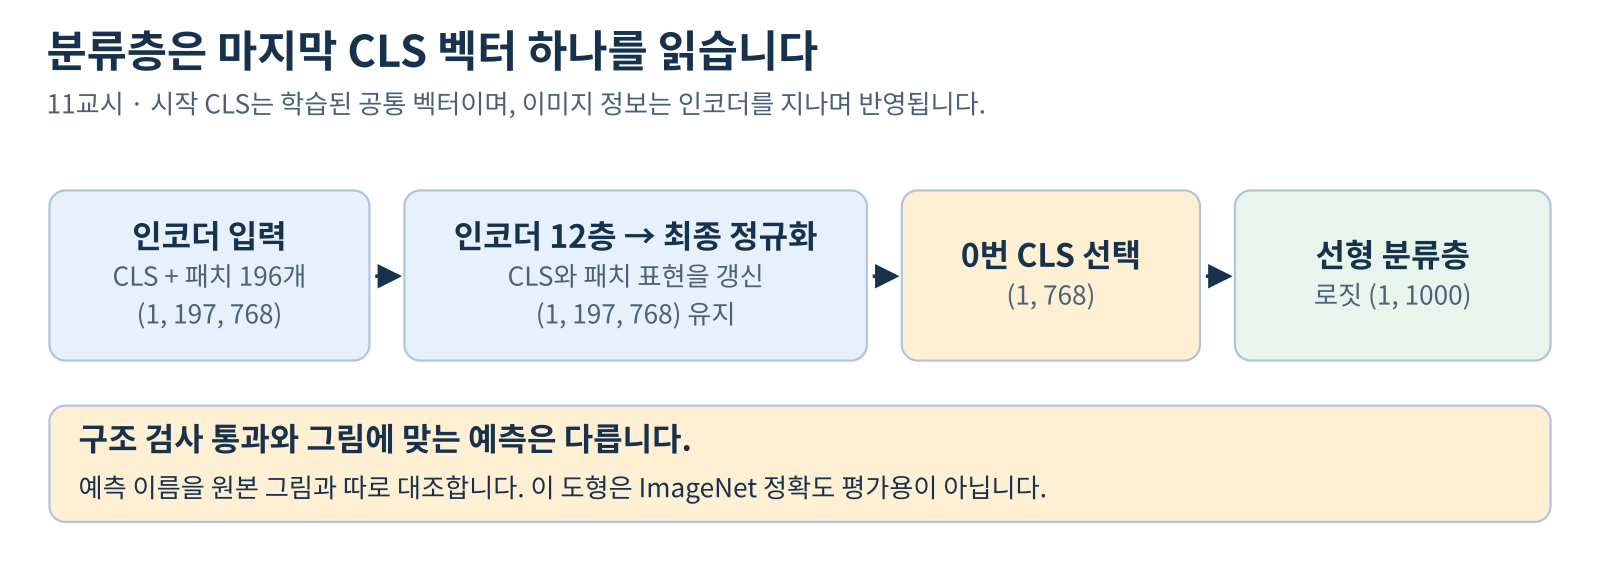

**그림 설명:** 첫 위치(CLS)에 표시한 색을 따라가 보세요. 다른 196개 위치도 인코더 출력에 남지만 분류 헤드에는 CLS만 들어갑니다.


### 코드 설명: 최종 CLS에서 분류 점수까지

`model.vit(...).last_hidden_state`에서 `encoded[:, 0, :]`으로 CLS를 꺼냅니다. 직접 분류층에 넣어 얻은 `logits_from_cls`와 전체 모델의 `logits`를 대조합니다.

**이 비교의 허용 오차:** `assert_close(logits, logits_from_cls, rtol=1e-4, atol=1e-5)`는 전체 분류 모델의 점수와 CLS를 직접 분류층에 넣은 점수를 비교합니다. 기준은 두 번째 인수 `logits_from_cls`이며, 각 차이에 `0.00001 + 0.0001 × |기준 점수|`를 허용합니다. 여기의 상대 항은 기준 크기의 0.01%입니다. 같은 분류 계산을 두 경로로 수행한 결과가 가까운지 보는 수치 검사이므로, 통과해도 예측 클래스가 원본 그림의 정답이라는 뜻은 아닙니다. [PyTorch assert_close의 판정식](https://docs.pytorch.org/docs/2.9/testing.html#torch.testing.assert_close)을 적용합니다.


In [5]:
# 이 시점부터 최고 할당량을 다시 집계하며 이미 올라온 모델 메모리는 포함됩니다.
torch.cuda.reset_peak_memory_stats()
with torch.inference_mode():
    # 인코더는 CLS와 패치의 197개 위치를 유지하면서 각 768차원 표현을 갱신합니다.
    encoded = model.vit(pixel_values=pixels, return_dict=True).last_hidden_state
    # 토큰 전체가 아니라 최종 CLS 위치의 벡터를 분류기에 전달합니다.
    # 0번 CLS의 768차원 벡터를 ImageNet 1000개 클래스 점수로 바꿉니다.
    logits_from_cls = model.classifier(encoded[:, 0, :])
    logits = model(pixel_values=pixels, return_dict=True).logits
assert tuple(encoded.shape) == (1, 197, 768)
assert tuple(logits.shape) == (1, 1000)
# NaN·무한대가 없는 수치인지 확인한 뒤 경로 간 값 일치를 검사합니다.
assert torch.isfinite(encoded).all() and torch.isfinite(logits).all()
# 두 경로의 수치 일치 검사이며 분류 정답 판정은 아닙니다.
# 기준은 logits_from_cls이며 각 차이에 0.00001+0.0001×|기준값|을 허용합니다.
torch.testing.assert_close(logits, logits_from_cls, rtol=1e-4, atol=1e-5)
# 가장 큰 점수의 클래스 번호를 고릅니다. 선택된 이름이 실제 도형과 맞는지는 별도로 판단합니다.
predicted_id = int(logits.argmax(-1).item())
print("encoder output:", tuple(encoded.shape))
print("final CLS:", tuple(encoded[:, 0, :].shape))
print("class logits:", tuple(logits.shape))
print("top class (accuracy score 아님):", model.config.id2label[predicted_id])
print("[PASS] final CLS -> pretrained classifier -> 1000 logits")

encoder output: (1, 197, 768)
final CLS: (1, 768)
class logits: (1, 1000)
top class (accuracy score 아님): envelope
[PASS] final CLS -> pretrained classifier -> 1000 logits


### 출력 설명

직접 CLS를 넣어 계산한 점수와 전체 모델의 점수가 허용 오차 안에서 일치해 PASS가 나왔습니다. 최상위 예측 `envelope`(봉투)는 빨간 사각형과 파란 원이 있는 그림과 맞지 않았습니다. **계산 경로의 통과와 분류 예측이 맞는지는 별개**입니다. 이 도형 한 장으로 ImageNet 분류 성능을 평가할 수는 없습니다.


## 6. 이미지가 바뀌어도 처음 CLS는 같을까요?

원본과 좌우 반전 이미지를 같은 크기로 전처리합니다. 인코더 전 CLS에는 두 경우 모두 같은 학습 CLS 벡터와 같은 0번 위치 임베딩이 쓰입니다. 그러나 같은 위치 번호에 놓인 패치 내용은 달라질 수 있으므로, 패치들과 정보를 주고받은 마지막 CLS도 달라질 수 있습니다. 이 비교는 한 입력 쌍에서 표현이 바뀌는지를 보는 것이며, 위치 임베딩만의 효과나 분류의 반전 강건성을 따로 검증하지 않습니다.


### 코드 설명: 시작 CLS는 같아도 최종 CLS는 달라집니다

`embeddings[:, 1:, :]`는 위치 임베딩을 더한 뒤 CLS를 뺀 패치 벡터열입니다. 원본과 반전 이미지에서 **같은 위치 번호끼리** 대응시키며 좌우를 다시 맞춰 비교하지 않습니다. 따라서 아래 패치 변화량은 투영 직후 원시 값만의 차이가 아닙니다.

`patch input mean absolute change`와 `final CLS mean absolute change`는 대응 원소 차이의 절댓값을 평균한 값입니다. 이는 정답률도 유사도 백분율도 아닙니다. `[PASS] same initial CLS; image-dependent final CLS`는 이 입력 쌍에서 이미지에 따라 최종 표현이 바뀐다는 증거입니다. 다만 반전은 내용의 위치도 함께 바꾸므로 이 실험만으로 위치 임베딩의 효과만을 독립적으로 측정했다고 말하지 않습니다.

**이 비교의 허용 오차:** `assert_close(embeddings[:, 0, :], flipped_embeddings[:, 0, :])`는 인코더 이전 CLS를 비교하며, 기준은 반전 이미지 쪽 `flipped_embeddings[:, 0, :]`입니다. 두 FP32 텐서에는 기본값 `atol=1e-5`, `rtol=1.3e-6`을 적용하여 각 차이가 `0.00001 + 0.0000013 × |반전 쪽 초기 CLS 값|` 이하인지 확인합니다. 같은 학습 CLS와 같은 위치 벡터로 시작하는지 검증하는 것입니다. 반면 뒤의 `patch_delta > 0`과 `cls_delta > 0`은 평균 절댓값 변화량이 양수인지 확인할 뿐, 이 허용 오차를 사용하는 검사가 아닙니다. [PyTorch의 FP32 기본 허용 오차](https://docs.pytorch.org/docs/2.9/testing.html#torch.testing.assert_close)와 구분해서 읽으세요.


In [6]:
# 오른쪽/왼쪽을 바꾸면 원소 개수는 같아도 위치와 내용의 조합이 달라집니다.
flipped = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
# 같은 전처리 규칙으로 반전 이미지를 준비하여 크기 변경이 아니라 위치·내용 변화에 집중합니다.
flipped_pixels = processor(images=flipped, return_tensors="pt")["pixel_values"].to(DEVICE, dtype=DTYPE)
with torch.inference_mode():
    flipped_embeddings = emb(flipped_pixels)
    flipped_encoded = model.vit(pixel_values=flipped_pixels, return_dict=True).last_hidden_state
# 인코더 이전 CLS는 학습된 같은 시작 벡터+같은 위치 벡터입니다.
# FP32 기본값 atol=1e-5, rtol=1.3e-6이며 반전 이미지의 초기 CLS가 기준입니다.
torch.testing.assert_close(embeddings[:, 0, :], flipped_embeddings[:, 0, :])
# 이 수치는 벡터 변화량이며 정확도나 확률을 뜻하지 않습니다.
# CLS를 제외한 모든 패치 원소의 평균 절댓값 차이를 계산합니다.
patch_delta = float((embeddings[:, 1:, :] - flipped_embeddings[:, 1:, :]).abs().mean())
# 어텐션을 거친 최종 CLS를 비교하므로 동일한 초기 CLS 검사와 구분합니다.
cls_delta = float((encoded[:, 0, :] - flipped_encoded[:, 0, :]).abs().mean())
# 변화량이 양수인지 확인할 뿐 큰 값이 좋은 분류나 높은 정확도를 뜻하지는 않습니다.
assert patch_delta > 0 and cls_delta > 0
print("patch input mean absolute change:", round(patch_delta, 6))
print("final CLS mean absolute change:", round(cls_delta, 6))
print("[PASS] same initial CLS; image-dependent final CLS")

patch input mean absolute change: 0.459622
final CLS mean absolute change: 0.084732
[PASS] same initial CLS; image-dependent final CLS


### 출력 설명

좌우 반전 전후 패치 입력의 평균 절댓값 차이는 0.459622, 마지막 CLS 차이는 0.084732로 둘 다 0보다 컸습니다. 초기 CLS는 같다는 값 비교도 통과했으므로, 같은 시작 벡터라도 인코더를 지나며 이미지 내용에 따라 다른 표현이 된 사례입니다.

이 두 값은 대응 원소의 평균 변화량이며 정확도나 유사도 백분율이 아닙니다. 반전은 내용과 위치의 조합을 함께 바꾸므로 위치 임베딩 하나의 효과만 분리해 측정했다거나 반전 강건성을 입증했다고 말할 수 없습니다.

초기 CLS 일치 검사는 반전 쪽 초기 CLS를 기준으로 `atol=0.00001`, `rtol=0.0000013`을 적용했습니다. 뒤의 두 변화량은 별도의 평균 절댓값 차이이며, 위 허용 오차와 비교한 정답 점수가 아닙니다.


## 7. 결과 저장
`results/lesson11-result.json`은 모델 revision, 텐서 모양, GPU 메모리 관측값을 남깁니다. peak allocated는 PyTorch가 추적한 할당량이지 그래픽카드 전체 사용량이 아닙니다. 모든 assert를 통과한 뒤에만 PASS 파일을 작성합니다.

### 코드 설명: 무엇을 검증했는지 남기기

`lesson11-result.json`에는 실행 환경, 입력·패치·encoder·logits의 shape, 반전 전후 변화량을 기록합니다. shape들을 연결해 “픽셀 → 196개 패치 → CLS 포함 197개 토큰 → 1000개 분류 점수” 흐름을 자신의 말로 설명해 보세요. `visual_accuracy_evaluated=False`는 정확도 평가를 수행하지 않았다는 명시적인 제한입니다.

`peak_allocated_mib`는 지정한 reset 이후 PyTorch가 관찰한 GPU 할당 메모리의 최고치입니다. reset 전에 이미 살아 있는 모델 메모리도 포함할 수 있지만, 모델 로딩 전체의 최고치나 다른 프로그램까지 포함한 GPU 전체 사용량은 아닙니다. 결과를 보관한 뒤 다음 모델을 올리기 전에 커널과 모델 참조를 정리합니다.


In [7]:
# GPU 작업을 마친 뒤 메모리 집계를 읽어 비동기 실행 중간의 값을 피합니다.
torch.cuda.synchronize()
# 구조 검사 통과와 시각 정확도 평가 여부를 서로 다른 항목으로 남깁니다.
# 텐서 전체 대신 shape와 변화량·실행 조건을 저장합니다.
report = {
    "lesson": 11, "status": "PASS", "model_id": MODEL_ID, "revision": REVISION,
    "torch": torch.__version__, "transformers": transformers.__version__, "cuda": torch.version.cuda,
    "device": DEVICE, "dtype": str(DTYPE),
    "pixel_shape": list(pixels.shape), "patch_shape": list(patch_tokens.shape),
    "embedding_shape": list(embeddings.shape), "encoder_shape": list(encoded.shape),
    "logits_shape": list(logits.shape), "patch_change": patch_delta, "cls_change": cls_delta,
    # 바이트를 1024²로 나눈 MiB입니다. 이 프로세스의 PyTorch 할당량이지 GPU 전체 사용량은 아닙니다.
    "peak_allocated_mib": round(torch.cuda.max_memory_allocated()/1024**2, 2),
    "visual_accuracy_evaluated": False
}
# 한글을 유지하는 JSON을 UTF-8 파일로 남깁니다. 아래 print는 같은 내용의 화면 확인입니다.
(OUT / "lesson11-result.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(report, ensure_ascii=False, indent=2))
# 다음 교시에서는 이 커널을 종료하고 새 커널에서 다른 모델을 불러옵니다.

{
  "lesson": 11,
  "status": "PASS",
  "model_id": "google/vit-base-patch16-224",
  "revision": "3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3",
  "torch": "2.9.1+cu126",
  "transformers": "5.23.0",
  "cuda": "12.6",
  "device": "cuda",
  "dtype": "torch.float32",
  "pixel_shape": [
    1,
    3,
    224,
    224
  ],
  "patch_shape": [
    1,
    196,
    768
  ],
  "embedding_shape": [
    1,
    197,
    768
  ],
  "encoder_shape": [
    1,
    197,
    768
  ],
  "logits_shape": [
    1,
    1000
  ],
  "patch_change": 0.45962244272232056,
  "cls_change": 0.08473171293735504,
  "peak_allocated_mib": 351.46,
  "visual_accuracy_evaluated": false
}


### 출력 설명

보고서의 패치 196개·CLS 포함 197개·클래스 점수 1000개는 앞에서 관찰한 경로를 연결해 기록합니다. `status=PASS`와 `visual_accuracy_evaluated=false`가 함께 있는 것은 모순이 아닙니다. 계산 경로를 검증했지만 별도 정확도 평가를 하지 않았다는 구분입니다.

`peak_allocated_mib`의 351.46 MiB는 최고치 집계를 초기화한 뒤 PyTorch가 관찰한 할당량입니다. 가중치를 처음 내려받고 올리는 전 과정의 최대치나 장치 전체 사용량이 아닙니다. JSON은 shape·변화량·실행 조건의 저장 기록이며 모든 중간 텐서나 분류 정확도 표를 저장한 것은 아닙니다.


## 문제 해결

- 패치 수 mismatch: `pixels.shape`와 고정 model revision을 확인합니다. 크기를 임의로 바꾸지 않습니다.
- 패키지 import 오류: 선택 커널과 정확한 버전을 확인합니다. 설치 명령을 추가하지 않습니다.
- CUDA 메모리 오류: 앞 교시 커널을 종료하고 이 Notebook을 새 커널에서 처음부터 실행합니다. 다른 프로세스를 강제 종료하지 않습니다.
- 다운로드 실패: 인증 토큰·개인정보를 입력하지 않습니다. 공개 모델 접근과 캐시를 강사와 확인하고 성공한 척 다음 단계로 넘어가지 않습니다.


## 정리와 자기 점검
- 설명해 보세요: 196→197은 무엇이 추가된 것인가요? 768→1000은 토큰 수 변화인가요?

   **핵심 답과 이유:** 196개 패치 앞에 CLS 한 개를 붙여 197개 위치가 됐습니다. 768→1000은 토큰 수 변화가 아니라 최종 CLS의 768차원 벡터를 분류층이 1000개 클래스 점수로 바꾼 것입니다. 실제 출력은 encoder `(1,197,768)`→CLS `(1,768)`→logits `(1,1000)`이었습니다.

- CLS는 사람이 지정한 정답 라벨이 아니라 모델이 학습하는 특별한 벡터입니다.

다음 교시의 VLM은 클래스 점수 하나를 고르는 대신 시각 벡터를 언어 모델에 전달해 문장을 생성합니다. 같은 그림을 써도 출력 과제가 달라진다는 점을 비교합니다.


## 참고: 이미지 크기가 달라지면 위치 정보는 어떻게 넣을까요?

이 참고 설명은 이번 실습에서 실행하지 않습니다. 실습에서는 모든 이미지를 224×224로 맞추므로, 모델이 학습한 위치 벡터를 그대로 씁니다.

**패치가 늘어나면 왜 위치 벡터가 더 필요할까요?** 패치마다 이미지 속 자리를 알려 주는 ‘자리표’가 하나씩 필요합니다. 이 자리표가 위치 벡터입니다. 16×16 패치를 쓰면 224×224 이미지는 세로 14칸, 가로 14칸이어서 자리표 196개가 필요합니다. 반면, 224×320 이미지를 224×224로 줄이지 않고 그대로 넣는다고 가정하면 세로 14칸은 그대로지만 가로가 20칸으로 늘어 자리표가 280개 필요합니다. 기존 14×14 격자의 자리표 196개를 그대로 짝지을 수는 없습니다.

**보간(interpolation)은 무엇을 바꿀까요?** 기존 14×14 자리표를 격자에 놓고, 새 14×20 격자의 각 칸에 들어갈 위치 벡터를 주변 자리표의 값을 참고해 계산합니다. 바뀌는 것은 자리표의 개수(196→280)입니다. 이미지를 늘리는 작업이 아니며, 위치 벡터 하나의 길이도 768로 같습니다. `[CLS]`는 이미지 패치가 아니므로 기존 위치 벡터를 따로 그대로 씁니다. [ViT 논문 §3.2](https://arxiv.org/html/2010.11929#S3.SS2)에서도 해상도를 높일 때 학습한 패치 위치 벡터를 2차원으로 보간했습니다. 224×320은 설명용 예이며, 실습 코드가 이 해상도를 자동 지원한다는 뜻은 아닙니다.

### 다른 비전 모델은 위치 정보를 어디에 넣을까요?

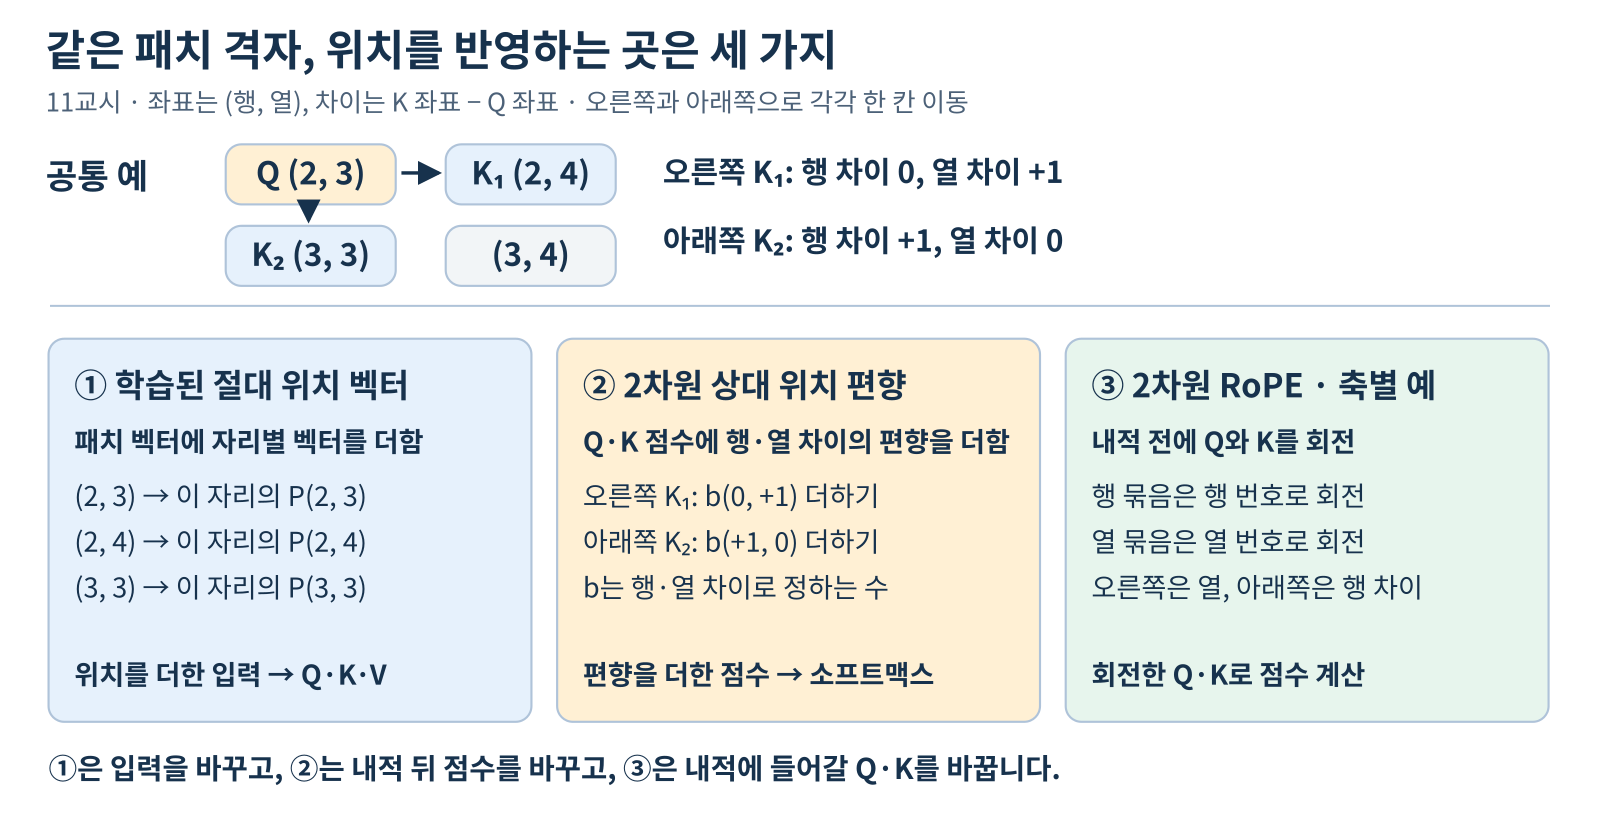

**그림 설명:** 같은 두 이웃을 놓고 위치 정보가 들어가는 곳을 비교합니다. 절대 위치 벡터는 각 패치 입력에 더한 뒤 Q·K·V를 만들고, 상대 위치 편향은 행·열 차이로 정한 값을 Q와 K의 내적에서 얻은 점수에 더한 뒤 소프트맥스를 합니다. 축별 2D RoPE는 그 점수를 계산하기 전에 Q와 K를 회전합니다. 앞에서 다룬 보간은 절대 위치 벡터를 새 격자에서 준비하는 방법이며, 네 번째 위치 표현이 아닙니다.

| 방법 | 위치 정보가 들어가는 곳 | 예시 |
|---|---|---|
| 절대 위치 임베딩 | 패치가 놓인 자리의 벡터를 입력에 더합니다. | [ViT §3.1](https://arxiv.org/html/2010.11929#S3.SS1) |
| 상대 위치 편향 | 두 패치의 행·열 차이로 정한 값을, 소프트맥스 전에 어텐션 점수에 더합니다. | [Swin V2 §3.3](https://arxiv.org/pdf/2111.09883#page=5) |
| 2차원 회전 위치 표현(2D RoPE) | 각 패치의 행·열 좌표에 따라 쿼리(Q)와 키(K)를 회전한 뒤 점수를 계산합니다. | [DINOv3의 ViT §3.2](https://arxiv.org/html/2508.10104#S3.SS2) |

#### 2차원 RoPE: 같은 행의 이웃과 같은 열의 이웃을 어떻게 구분할까요?

RoPE는 입력에 위치 벡터를 더하는 대신, **어텐션에서 점수를 계산하기 직전에 Q(쿼리)와 K(키)의 성분을 회전**합니다. 예를 들어 행과 열을 따로 쓰는 [축별 2차원 RoPE(Axial RoPE)](https://arxiv.org/html/2403.13298#S3.SS2)는 Q와 K의 회전 대상 성분쌍을 **행을 맡는 묶음과 열을 맡는 묶음**으로 나눕니다. 행 묶음은 패치의 행 번호로, 열 묶음은 열 번호로 회전 각도를 정합니다. 여기서는 각 축을 따로 맡기는 방식을 예로 들며, 모든 2D RoPE가 같은 방식으로 차원을 나누는 것은 아닙니다. 점수에 따라 섞어 읽을 내용인 **V(값)는 회전하지 않습니다.**

패치 좌표를 **(행, 열)**로 씁니다. 기준 Q가 **(2, 3)**에 있을 때, **(2, 4)**의 K는 같은 행에서 오른쪽 한 칸이므로 행·열 차이는 **(0, +1)**입니다. **(3, 3)**의 K는 같은 열에서 아래쪽 한 칸이므로 **(+1, 0)**입니다. 첫 비교는 열 묶음에만 상대 회전 차이가 있고, 두 번째 비교는 행 묶음에만 차이가 있습니다.

Q와 K를 각각 자기 좌표로 회전한 다음 내적하면, 같은 축에서 두 회전의 공통 부분은 상쇄되고 **두 좌표의 차이만큼의 상대 회전**이 남습니다. 그래서 오른쪽 한 칸과 아래쪽 한 칸이 다른 축을 통해 어텐션 점수에 반영될 수 있습니다. 점수에는 패치 내용도 들어가므로, 오프셋만 알면 점수가 정해지거나 거리가 멀수록 점수가 낮아지는 것은 아닙니다.

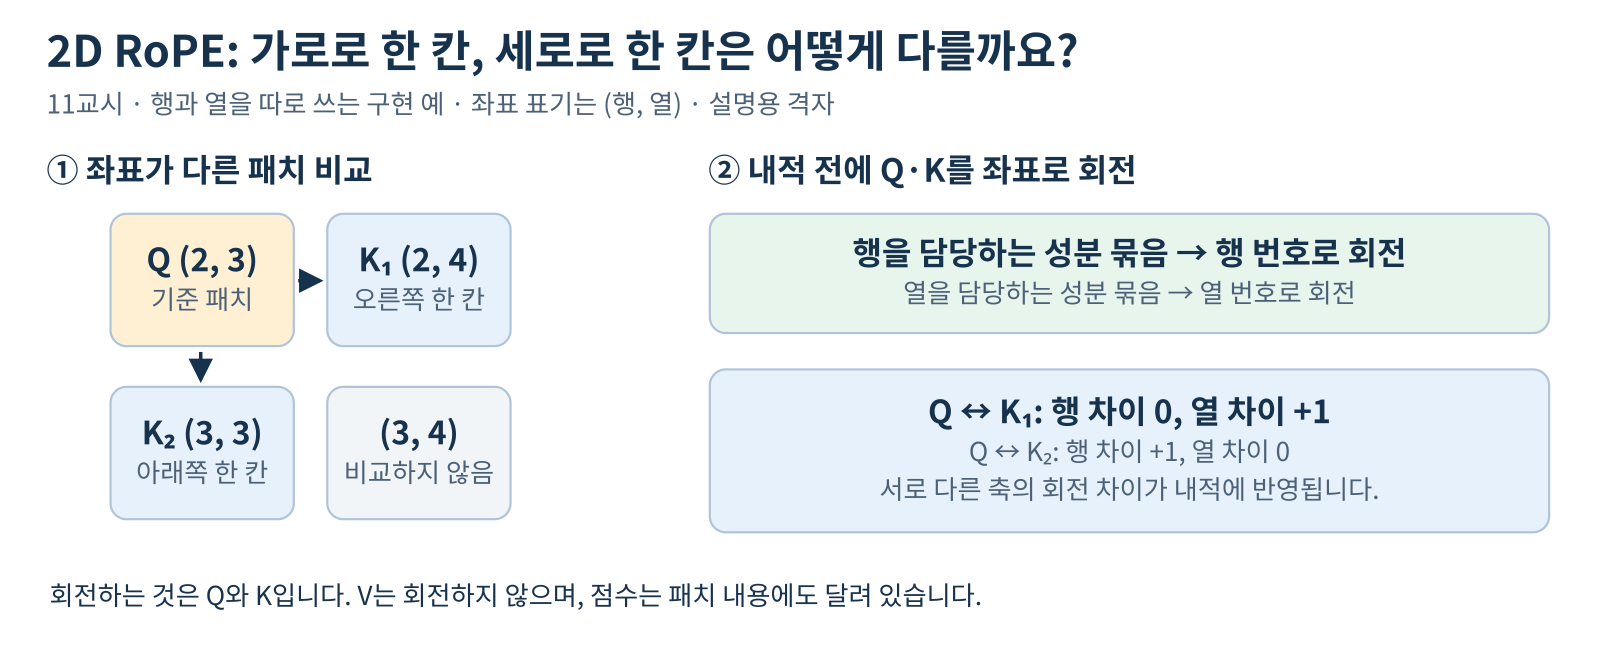

**위치 벡터 보간과의 차이:** 앞의 보간은 이미 학습한 **입력 위치 표**에서 새 격자의 위치 벡터를 만들어 패치 벡터에 더하는 방법입니다. 이 2D RoPE 예시는 위치 표를 보간하는 대신, **어텐션 내부**에서 좌표로 Q와 K의 회전을 정합니다. 이미지·영상의 격자와 크기가 다양할 때, 가로·세로 어디에 있는지 모델에 어떻게 알려 줄지는 시각 설계의 중요한 선택입니다. 실습의 ViT-B/16은 학습된 절대 위치 임베딩을 쓰므로 이 회전을 실행하지 않습니다.

**실제 모델에서는 어떻게 쓸까요?**

- [Pixtral 12B 비전 인코더](https://arxiv.org/html/2410.07073#S2.SS2)는 학습된 절대 위치 임베딩 대신 2D RoPE를 씁니다.
- [Qwen3-VL 비전 인코더](https://arxiv.org/html/2511.21631#S2)는 입력 크기에 맞춰 보간한 절대 위치 임베딩과 어텐션의 2D RoPE를 함께 씁니다. 언어 모델의 시간·높이·너비를 다루는 Interleaved MRoPE는 이와 별개입니다.
- [Gemma 4 E2B/E4B 비전 인코더](https://arxiv.org/html/2607.02770#S2.SS1)는 2D 절대 위치 임베딩과 축별 2D RoPE를 함께 씁니다. 이 설명은 별도 비전 인코더가 없는 12B Unified에는 해당하지 않습니다.


## 참고 자료

- **ViT 구조와 논문 결과:** [ViT 원 논문 §3.1: 구조](https://arxiv.org/html/2010.11929#S3.SS1) · [§3.2: 해상도와 위치 보간](https://arxiv.org/html/2010.11929#S3.SS2) · [표 2: 정확도 비교](https://arxiv.org/pdf/2010.11929#page=6)
- **원래 Transformer:** [§3.1: 인코더와 디코더](https://arxiv.org/html/1706.03762#S3.SS1) · [§3.3: FFN](https://arxiv.org/html/1706.03762#S3.SS3) · [§3.5: 위치 인코딩](https://arxiv.org/html/1706.03762#S3.SS5)
- **실습 체크포인트:** [공식 모델 카드](https://huggingface.co/google/vit-base-patch16-224) · [고정 모델 설정](https://huggingface.co/google/vit-base-patch16-224/blob/3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3/config.json) · [고정 전처리 설정](https://huggingface.co/google/vit-base-patch16-224/blob/3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3/preprocessor_config.json)
- **Transformers 5.23.0 구현:** [패치 투영과 위치 임베딩](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/vit/modeling_vit.py#L42-L160) · [인코더 블록](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/vit/modeling_vit.py#L257-L298) · [CLS 분류](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/vit/modeling_vit.py#L515-L573)
- **수치 검사:** [PyTorch의 `torch.testing.assert_close` 판정식과 기본 허용 오차](https://docs.pytorch.org/docs/2.9/testing.html#torch.testing.assert_close)
- **위치 정보 확장 참고:** [Swin V2 §3.3: 상대 위치 편향](https://arxiv.org/pdf/2111.09883#page=5) · [DINOv3 §3.2: 2D RoPE](https://arxiv.org/html/2508.10104#S3.SS2) · [Qwen3-VL §2: 비전 인코더](https://arxiv.org/html/2511.21631#S2)
